#### Notebook 4: ARIMA Forecasting
**Goal:** Build the first forecasting model and measure how good it is.
ARIMA predicts future values from past values of the same series.
We split the data **in time order** (never randomly): the last 28 days are the test set.
We also compare with a **naive baseline** (tomorrow = today). A model is useful only if it beats this.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

In [2]:
warnings.filterwarnings("ignore")

In [3]:
clean = pd.read_csv("../01_Data/processed/cleaned_data.csv", parse_dates=["Date"])
MAIN = ["Delhi", "Lucknow", "Bengaluru", "Chennai", "Hyderabad"]

In [4]:
def get_series(city):
    s = clean[clean["City"] == city].set_index("Date")["AQI"].sort_index()
    return s.asfreq("D").interpolate(limit=7).dropna()

delhi = get_series("Delhi")
print(delhi.shape, delhi.index.min().date(), delhi.index.max().date())

(2009,) 2015-01-01 2020-07-01


**** ARIMA needs a stable series. If the p-value is below 0.05 the series is already stable (d = 0), otherwise we difference it (d = 1).

In [5]:
p = adfuller(delhi)[1]
print("ADF p-value:", round(p, 4))
D = 0 if p < 0.05 else 1
print("d =", D)

ADF p-value: 0.0099
d = 0


In [6]:
# Train/test split
TEST_DAYS = 28
train, test = delhi.iloc[:-TEST_DAYS], delhi.iloc[-TEST_DAYS:]
print("Train:", len(train), "days | Test:", len(test), "days")


Train: 1981 days | Test: 28 days


We try small p and q values and keep the one with the lowest AIC (lower = better balance of accuracy and simplicity).

In [7]:
best = None
for pp in range(0, 4):
    for qq in range(0, 4):
        try:
            fit = ARIMA(train, order=(pp, D, qq)).fit()
            if best is None or fit.aic < best[0]:
                best = (fit.aic, (pp, D, qq))
        except Exception:
            pass
print("Best order (p, d, q):", best[1], "| AIC:", round(best[0], 1))

Best order (p, d, q): (2, 0, 2) | AIC: 21119.0


The app forecasts 7 days ahead, so we test the same way: predict 7 days, reveal the real 7 days, repeat 4 times.

In [8]:
def rolling_forecast(train, test, order, horizon=7):
    res = ARIMA(train, order=order).fit()
    preds = []
    for i in range(0, len(test), horizon):
        chunk = test.iloc[i:i + horizon]
        preds.append(res.forecast(len(chunk)))
        res = res.append(chunk, refit=False)
    return pd.concat(preds)

def naive_forecast(train, test, horizon=7):
    last = train.iloc[-1]
    preds = []
    for i in range(0, len(test), horizon):
        chunk = test.iloc[i:i + horizon]
        preds.append(pd.Series(last, index=chunk.index))
        last = chunk.iloc[-1]
    return pd.concat(preds)

def metrics(actual, pred):
    err = actual - pred
    return {"RMSE": round(float(np.sqrt((err ** 2).mean())), 1),
            "MAE": round(float(err.abs().mean()), 1)}

pred_arima = rolling_forecast(train, test, best[1])
pred_naive = naive_forecast(train, test)
print("ARIMA:", metrics(test, pred_arima))
print("Naive:", metrics(test, pred_naive))

ARIMA: {'RMSE': 37.6, 'MAE': 27.0}
Naive: {'RMSE': 46.0, 'MAE': 30.6}


Graph

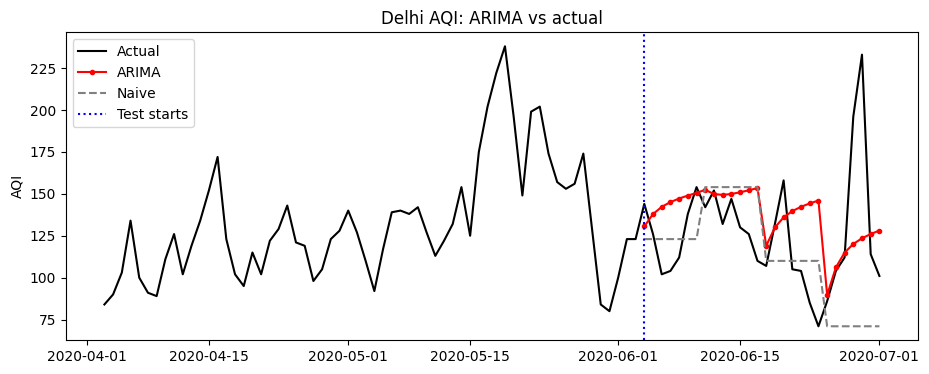

In [9]:
plt.figure(figsize=(11, 4))
plt.plot(delhi.iloc[-90:], label="Actual", color="black")
plt.plot(pred_arima, label="ARIMA", color="red", marker="o", markersize=3)
plt.plot(pred_naive, label="Naive", color="gray", linestyle="--")
plt.axvline(test.index.min(), color="blue", linestyle=":", label="Test starts")
plt.title("Delhi AQI: ARIMA vs actual")
plt.ylabel("AQI")
plt.legend()
plt.show()

All 5 cities 

In [13]:
import warnings
warnings.filterwarnings("ignore")

def get_series(city):
    s = clean[clean["City"] == city].set_index("Date")["AQI"].sort_index()
    s = s.asfreq("D").interpolate(limit=7)
    missing = s.isna()
    if missing.any():                                   # bade gap ke baad ka hissa rakho
        s = s.loc[missing[missing].index.max() + pd.Timedelta(days=1):]
    s = s.asfreq("D")
    s.index = pd.DatetimeIndex(s.index, freq="D")       # regular daily index pakka karo
    return s

def rolling_forecast(train, test, order, horizon=7):
    res = ARIMA(train, order=order).fit()
    preds = []
    for i in range(0, len(test), horizon):
        chunk = test.iloc[i:i + horizon]
        preds.append(res.forecast(len(chunk)))
        res = res.append(chunk, refit=False)
    return pd.concat(preds)

def naive_forecast(train, test, horizon=7):
    last = train.iloc[-1]
    preds = []
    for i in range(0, len(test), horizon):
        chunk = test.iloc[i:i + horizon]
        preds.append(pd.Series(last, index=chunk.index))
        last = chunk.iloc[-1]
    return pd.concat(preds)

def metrics(actual, pred):
    err = actual - pred
    return {"RMSE": round(float(np.sqrt((err ** 2).mean())), 1),
            "MAE": round(float(err.abs().mean()), 1)}

TEST_DAYS = 28
rows = []

for city in MAIN:
    try:
        s = get_series(city)
        print(city, "|", len(s), "days |", s.index.min().date(), "to", s.index.max().date())

        if len(s) < 365:
            print("   Skipped: less than 1 year of continuous data")
            continue

        tr, te = s.iloc[:-TEST_DAYS], s.iloc[-TEST_DAYS:]
        d = 0 if adfuller(tr)[1] < 0.05 else 1

        best_c = None
        for pp in range(0, 3):
            for qq in range(0, 3):
                try:
                    f = ARIMA(tr, order=(pp, d, qq)).fit()
                    if best_c is None or f.aic < best_c[0]:
                        best_c = (f.aic, (pp, d, qq))
                except Exception:
                    pass

        m  = metrics(te, rolling_forecast(tr, te, best_c[1]))
        mn = metrics(te, naive_forecast(tr, te))
        rows.append({"City": city, "Model": "ARIMA", "Order": best_c[1],
                     "RMSE": m["RMSE"], "MAE": m["MAE"], "Naive_RMSE": mn["RMSE"],
                     "Days_used": len(s)})
        print("   done")

    except Exception as e:
        print("   FAILED:", type(e).__name__, "-", str(e)[:150])

arima_results = pd.DataFrame(rows)
arima_results.to_csv("../01_Data/processed/arima_results.csv", index=False)
arima_results

Delhi | 2009 days | 2015-01-01 to 2020-07-01
   done
Lucknow | 1497 days | 2016-05-27 to 2020-07-01
   done
Bengaluru | 1930 days | 2015-03-21 to 2020-07-01
   done
Chennai | 1279 days | 2016-12-31 to 2020-07-01
   done
Hyderabad | 1399 days | 2016-09-02 to 2020-07-01
   done


,City,Model,Order,RMSE,MAE,Naive_RMSE,Days_used
0,Delhi,ARIMA,"(2, 0, 2)",37.6,27.0,46.0,2009
1,Lucknow,ARIMA,"(2, 0, 2)",39.9,35.9,51.3,1497
2,Bengaluru,ARIMA,"(2, 0, 1)",13.2,11.4,13.2,1930
3,Chennai,ARIMA,"(2, 0, 2)",23.9,15.8,26.6,1279
4,Hyderabad,ARIMA,"(2, 0, 2)",16.3,12.6,15.2,1399
